[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/notebooks/lecture7_notebook.ipynb)

# Blockchain Applications — Lecture 7: Machine learning, AI and their limits

*Lecture notebook. Daniel Traian Pele, Bucharest University of Economic Studies.*

This notebook reproduces the computations of Lecture 7 in the order of the slides:

1. can machine learning predict the direction of Bitcoin? Walk-forward classifiers, skill scores and a trading back-test;
2. data snooping: 810 trading rules, the deflated Sharpe ratio, a permutation illustration and White's reality check;
3. one-day Bitcoin Value-at-Risk (VaR) from classical, machine-learning and pretrained models, scored by breach rates and the quantile score;
4. the limits of machine learning (ML) and artificial intelligence (AI) in crypto finance;
5. appendix (not examined): correcting a VaR forecast with its own past errors, a Monte Carlo study and the Basel traffic light.

Data: daily Bitcoin closes and volumes from EODHD in the course repository (`data/market`), to **23 October 2026**.
Returns are daily log returns in per cent, $r_t = 100\,(\ln P_t - \ln P_{t-1})$.
Sign convention (as in Lecture 3): $q_t$ is the $\alpha$-quantile of tomorrow's return (a negative number) and $\mathrm{VaR}_t = -q_t$ is a positive loss.
"VaR 1%" is minus the 1% quantile of tomorrow's return. Charts plot the return quantile $q_t$, labelled as such.

> **Working in Google Colab? Save your own copy first.**
> The Colab link opens a temporary copy: when you close the tab or the session times out, your changes are lost.
> Use **File → Save a copy in Drive** (it goes to the *Colab Notebooks* folder of your Google Drive) and work in that copy.
> Files you create while the notebook runs (CSV files, charts) are also temporary: set `SAVE_TO_DRIVE = True` in the next cell to keep them.

In [ ]:
# Optional (Colab only): keep the files you create in Google Drive
SAVE_TO_DRIVE = False   # set to True, run this cell and allow access to your Drive

import os
OUT_DIR = '.'
if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    OUT_DIR = '/content/drive/MyDrive/Blockchain_Applications/Lecture_7'
    os.makedirs(OUT_DIR, exist_ok=True)
print('Save your outputs to:', os.path.abspath(OUT_DIR))

In [2]:
# packages that are not preinstalled on Colab
import importlib, subprocess, sys
for pkg in ['arch', 'shap', 'xgboost']:
    try:
        importlib.import_module(pkg)
    except ImportError:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', pkg], check=True)

## Setup: packages, chart style and data

In [3]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [4]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

### Lecture-specific setup

In [5]:
from scipy import stats
import statsmodels.api as sm
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier
import shap
from arch import arch_model

END = pd.Timestamp('2026-10-23')                       # last day of the lecture sample


def legend_at_bottom(fig, ncol=3, bottom=0.12):
    """Legend below the plot (shared helper), with room for it at the bottom of the figure."""
    legend_below(fig, ncol)
    fig.tight_layout(rect=(0, bottom, 1, 1))


btc = pd.read_csv(data_file('market', 'BTC-USD.CC.csv'), parse_dates=['date']).set_index('date').loc[:END]
r = (100 * np.log(btc['close'])).diff().dropna().loc['2015-01-01':]           # daily log return, %
lv = np.log(btc['volume'].replace(0, np.nan)).diff().reindex(r.index).fillna(0)  # daily change of log volume
print(f'Bitcoin daily log returns: {len(r)} days, {r.index[0].date()} to {r.index[-1].date()}')

Bitcoin daily log returns: 4314 days, 2015-01-01 to 2026-10-23


## 1. Can machine learning predict the direction of Bitcoin?

### The prediction problem

The target is tomorrow's direction, $y_{t+1} = \mathbb{1}\{r_{t+1} > 0\}$. The 13 features $x_t$ are known at today's close: the returns of the
last three days, 5-, 20- and 60-day momentum (sums of returns), 5- and 20-day volatility, today's change in log volume and its 5-day mean,
the gaps (in %) between the price and its 50- and 200-day moving averages, and the day of the week.

Three classifiers of increasing flexibility:

* logistic regression (logit), $P(y_{t+1} = 1 \mid x_t) = \Lambda(\beta_0 + x_t'\beta)$ with $\Lambda(u) = 1/(1 + e^{-u})$, standardised features and a ridge penalty;
* random forest: the average of $B = 500$ trees, each grown on a bootstrap sample with random subsets of features;
* gradient boosting (XGBoost): additive trees, $F_m(x) = F_{m-1}(x) + \eta\, h_m(x)$, each $h_m$ fitted to the gradient of the log-loss; $\eta = 0.05$, 300 trees of depth 3.

**Walk-forward design.** At each forecast origin $\tau$, train on all data up to $\tau$, predict the next 63 days, move $\tau$ forward by 63 days and refit.
The test period is 1 January 2020 – 22 October 2026 (the last day whose next-day return is known). Each forecast uses only information available
before its target day; test days that have been realised join the training data at later origins, which is not leakage. The cell prints the first two origins.

In [6]:
T0 = pd.Timestamp('2020-01-01')
COST = 0.10                                   # transaction cost, % per change of position (10 basis points)
c = btc['close'].reindex(r.index)
F = pd.DataFrame({'ret_1': r, 'ret_2': r.shift(1), 'ret_3': r.shift(2), 'mom_5': r.rolling(5).sum(), 'mom_20': r.rolling(20).sum(),
                  'mom_60': r.rolling(60).sum(), 'vol_5': r.rolling(5).std(), 'vol_20': r.rolling(20).std(),
                  'dvol': lv, 'dvol_5': lv.rolling(5).mean(), 'ma_gap_50': 100 * np.log(c / c.rolling(50).mean()),
                  'ma_gap_200': 100 * np.log(c / c.rolling(200).mean()), 'dow': r.index.dayofweek})
y = (r.shift(-1) > 0).astype(int)              # direction of tomorrow
ok = F.notna().all(axis=1) & r.shift(-1).notna()
F, y, rn = F[ok], y[ok], r.shift(-1)[ok]       # rn = tomorrow's return
Xv, yv, dates = F.values, y.values, F.index
test = np.where((dates >= T0) & (dates < END))[0]

MODELS = {'Logit': lambda: make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=2000)),
          'Random forest': lambda: RandomForestClassifier(n_estimators=500, max_depth=5, min_samples_leaf=20, random_state=1, n_jobs=-1),
          'XGBoost': lambda: XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                                           random_state=1, verbosity=0)}
P = {m: np.full(len(dates), np.nan) for m in MODELS}
acc_in = {m: [] for m in MODELS}
pbar_past = np.full(len(dates), np.nan)       # share of up days in the training data at each origin
origins = []
for b0 in range(test[0], test[-1] + 1, 63):
    b1 = min(b0 + 63, test[-1] + 1)
    tr = np.arange(0, b0)
    pbar_past[b0:b1] = yv[tr].mean()
    origins.append((dates[tr[-1]].date(), dates[b0].date(), dates[b1 - 1].date()))
    for m, mk in MODELS.items():
        mdl = mk().fit(Xv[tr], yv[tr])
        P[m][b0:b1] = mdl.predict_proba(Xv[b0:b1])[:, 1]
        acc_in[m].append(((mdl.predict_proba(Xv[tr])[:, 1] > 0.5) == yv[tr]).mean())
    last_xgb = mdl                             # the last model in the loop is XGBoost
print(f'Test period: {dates[test[0]].date()} to {dates[test[-1]].date()}, T = {len(test)} days; '
      f'{len(range(test[0], test[-1] + 1, 63))} refits of each model')
for k, (e, a, b) in enumerate(origins[:2], 1):
    print(f'origin {k}: train to {e}, predict {a} to {b}')

Test period: 2020-01-01 to 2026-10-22, T = 2487 days; 40 refits of each model
origin 1: train to 2019-12-31, predict 2020-01-01 to 2020-03-03
origin 2: train to 2020-03-03, predict 2020-03-04 to 2020-05-05


### Measuring predictive skill

* **Accuracy** $= T^{-1}\sum_t \mathbb{1}\{\hat y_t = y_t\}$, with $\hat y_t = \mathbb{1}\{p_t > 0.5\}$. It must beat the base rate: the share of up-days, which "always predict up" scores.
* **Brier score** of the probabilities $p_t$: $\mathrm{BS} = T^{-1}\sum_t (p_t - y_t)^2$. Two constant benchmarks: the share of up days in the
  test period, $p_t = \bar y$, gives $\bar y(1-\bar y) \approx 0.250$ but is known only ex post; the share of up days in the training data at each
  origin uses the past only.
* **AUC**, the area under the receiver operating characteristic curve: the probability that a random up-day gets a higher $p_t$ than a random down-day; 0.5 = no skill.
* **Pesaran–Timmermann (PT) test**: compares the hit rate $\hat P$ with the hit rate expected if forecasts and outcomes were independent,
  $P^* = \bar y\, \bar{\hat y} + (1-\bar y)(1-\bar{\hat y})$:
  $$ \mathrm{PT} = \frac{\hat P - P^*}{\sqrt{\widehat{V}(\hat P) - \widehat{V}(P^*)}} \;\overset{a}{\sim}\; N(0,1) \quad \text{(one-sided p-value).} $$
* **Trading**: long Bitcoin when $p_t > 0.5$, otherwise cash, with a cost of 10 basis points (bp) per change of position. Daily net return $g_t$;
  annualised Sharpe ratio (SR) $= \sqrt{365}\,\bar g / s_g$; maximum drawdown = largest fall of wealth from its running peak,
  $1 - e^{-D_{\log}/100}$, where $D_{\log}$ is the largest fall of the cumulative log return in log points (the definition of Lecture 2);
  turnover = position changes per year.
* Sampling error of an annualised SR over $Y$ years: $\mathrm{se} \approx \sqrt{(1 + \mathrm{SR}^2/2)/Y}$.

In [7]:
def pt_test(yhat, yobs):
    """Pesaran-Timmermann (1992) test of directional accuracy: statistic and one-sided p-value."""
    T = len(yobs); py, px = yobs.mean(), yhat.mean()
    ph = (yhat == yobs).mean()
    ps = py * px + (1 - py) * (1 - px)
    v1 = ps * (1 - ps) / T
    v2 = ((2 * py - 1) ** 2 * px * (1 - px) / T + (2 * px - 1) ** 2 * py * (1 - py) / T + 4 * py * px * (1 - py) * (1 - px) / T ** 2)
    s = (ph - ps) / np.sqrt(v1 - v2)
    return s, stats.norm.sf(s)


def perf(pos, ret):
    """Net daily returns of a position path after costs, and summary statistics."""
    tc = COST * np.abs(np.diff(np.r_[0, pos]))
    g = pos * ret - tc
    eq = np.cumsum(g)
    d_log = np.max(np.maximum.accumulate(eq) - eq)          # largest fall of cumulative log return, log points
    return dict(SR=g.mean() / g.std(ddof=1) * np.sqrt(365), max_drawdown=100 * (1 - np.exp(-d_log / 100)), d_log=d_log,
                ann_return=365 * g.mean(), turnover=np.abs(np.diff(np.r_[0, pos])).mean() * 365), g


yt, rt = yv[test], rn.values[test]
G, rows = {}, {}
bh, G['Buy and hold'] = perf(np.ones(len(test)), rt)
rows['Always up / buy and hold'] = {'acc in-sample (%)': np.nan, 'acc out-of-sample (%)': 100 * yt.mean(), 'AUC': 0.5,
                                   'Brier': yt.mean() * (1 - yt.mean()), 'PT p': np.nan, 'share long (%)': 100,
                                   'SR': bh['SR'], 'max drawdown (%)': bh['max_drawdown'], 'log decline (log points)': bh['d_log']}
by_year = {}
for m in MODELS:
    p = P[m][test]; yh = (p > 0.5).astype(int)
    s, pv = pt_test(yh, yt)
    pf, G[m] = perf(yh.astype(float), rt)
    rows[m] = {'acc in-sample (%)': 100 * np.mean(acc_in[m]), 'acc out-of-sample (%)': 100 * (yh == yt).mean(), 'AUC': roc_auc_score(yt, p),
               'Brier': np.mean((p - yt) ** 2), 'PT p': pv, 'share long (%)': 100 * yh.mean(), 'SR': pf['SR'], 'max drawdown (%)': pf['max_drawdown'],
               'log decline (log points)': pf['d_log']}
    yrs = dates[test].year
    by_year[m] = {int(Y): 100 * ((yh == yt)[yrs == Y]).mean() for Y in np.unique(yrs)}
res_ml = pd.DataFrame(rows).T
print(f'Base rate: Bitcoin rose on {100 * yt.mean():.1f}% of test days; Brier score of the constant forecast p = {yt.mean():.3f} (ex post): {np.mean((yt.mean() - yt) ** 2):.4f}')
print(f'Brier score of the past-only constant (share of up days in the training data, {pbar_past[test].min():.3f} to {pbar_past[test].max():.3f}): '
      f'{np.mean((pbar_past[test] - yt) ** 2):.4f}')
print('\nResults, test period (accuracy in %, max drawdown in % of wealth, SR annualised, after 10 bp costs):')
print(res_ml.round(4).to_string())
print('\nOut-of-sample accuracy by calendar year (%):')
print(pd.DataFrame(by_year).round(1).to_string())
Y = len(test) / 365
print(f'\nSampling error of an annualised Sharpe ratio over {Y:.1f} years (SR = 0.6): {np.sqrt((1 + 0.6 ** 2 / 2) / Y):.2f}')

Base rate: Bitcoin rose on 50.6% of test days; Brier score of the constant forecast p = 0.506 (ex post): 0.2500
Brier score of the past-only constant (share of up days in the training data, 0.526 to 0.556): 0.2510

Results, test period (accuracy in %, max drawdown in % of wealth, SR annualised, after 10 bp costs):
                          acc in-sample (%)  acc out-of-sample (%)     AUC   Brier    PT p  share long (%)      SR  max drawdown (%)  log decline (log points)
Always up / buy and hold                NaN                50.6232  0.5000  0.2500     NaN        100.0000  0.5910           76.6346                  145.3912
Logit                               55.7652                51.7491  0.5252  0.2515  0.0322         85.4443  0.7240           68.6160                  115.8872
Random forest                       64.5579                51.5883  0.5140  0.2514  0.0682         77.6437  0.8143           80.0248                  161.0680
XGBoost                             78.3121     

### Overfitting and what the model uses

**Shapley additive explanations (SHAP)** split a prediction into feature contributions, $f(x) = \phi_0 + \sum_j \phi_j(x)$, where $\phi_j$ is the
average marginal contribution of feature $j$ over all orderings of the features. The bar chart ranks features by mean $|\phi_j|$ for the last
XGBoost fit on the last 400 test days. SHAP explains the *model*, not the market: a large $|\phi_j|$ in a model with no skill is not evidence that the feature predicts returns.

The left panel compares in-sample accuracy (on the training data, averaged over the refits) with out-of-sample accuracy.

Mean |SHAP| of each feature, largest first (XGBoost, last 400 test days):
return today                0.0967
5-day volatility            0.0907
20-day momentum             0.0741
day of the week             0.0720
5-day momentum              0.0691
gap to 50-day average       0.0626
5-day mean volume change    0.0621
return 1 day ago            0.0589
20-day volatility           0.0566
return 2 days ago           0.0430
gap to 200-day average      0.0404
volume change today         0.0394
60-day momentum             0.0371


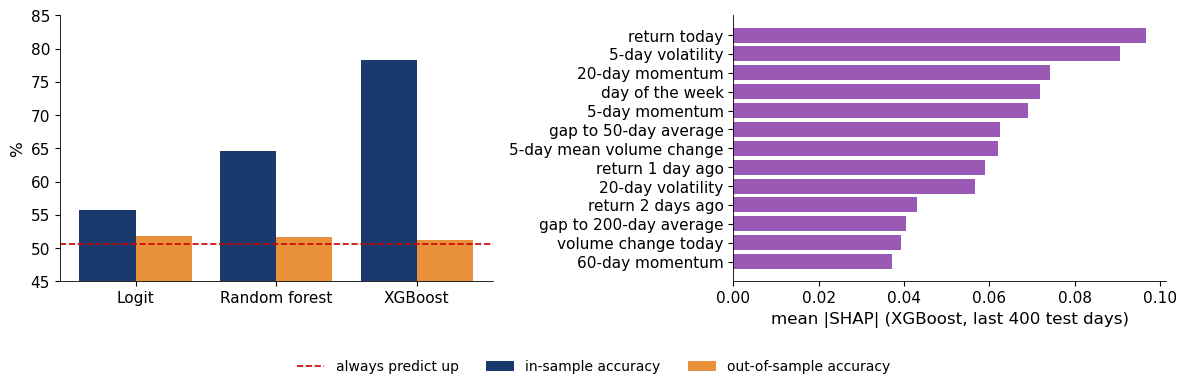

In [8]:
sv = shap.TreeExplainer(last_xgb).shap_values(Xv[test[-400:]])
imp = pd.Series(np.abs(sv).mean(axis=0), index=F.columns).sort_values()
LAB = {'ret_1': 'return today', 'ret_2': 'return 1 day ago', 'ret_3': 'return 2 days ago', 'mom_5': '5-day momentum',
       'mom_20': '20-day momentum', 'mom_60': '60-day momentum', 'vol_5': '5-day volatility', 'vol_20': '20-day volatility',
       'dvol': 'volume change today', 'dvol_5': '5-day mean volume change', 'ma_gap_50': 'gap to 50-day average',
       'ma_gap_200': 'gap to 200-day average', 'dow': 'day of the week'}
print('Mean |SHAP| of each feature, largest first (XGBoost, last 400 test days):')
print(imp[::-1].rename(LAB).round(4).to_string())

fig, ax = plt.subplots(1, 2, figsize=(12, 3.9))
ms = list(MODELS); x = np.arange(len(ms))
ax[0].bar(x - 0.2, res_ml.loc[ms, 'acc in-sample (%)'], 0.4, color=BLUE, label='in-sample accuracy')
ax[0].bar(x + 0.2, res_ml.loc[ms, 'acc out-of-sample (%)'], 0.4, color=BTC, label='out-of-sample accuracy')
ax[0].axhline(100 * yt.mean(), color=RED, ls='--', lw=1.2, label='always predict up')
ax[0].set_ylim(45, 85); ax[0].set_xticks(x); ax[0].set_xticklabels(ms); ax[0].set_ylabel('%')
ax[1].barh([LAB[k] for k in imp.index], imp.values, color=ETH)
ax[1].set_xlabel('mean |SHAP| (XGBoost, last 400 test days)')
legend_at_bottom(fig, ncol=3, bottom=0.1)
save_fig(fig, 'ba_l7_ml_acc')

### Trading the signals

Cumulative log return (%) of each strategy after costs, against buy-and-hold, over the test period.

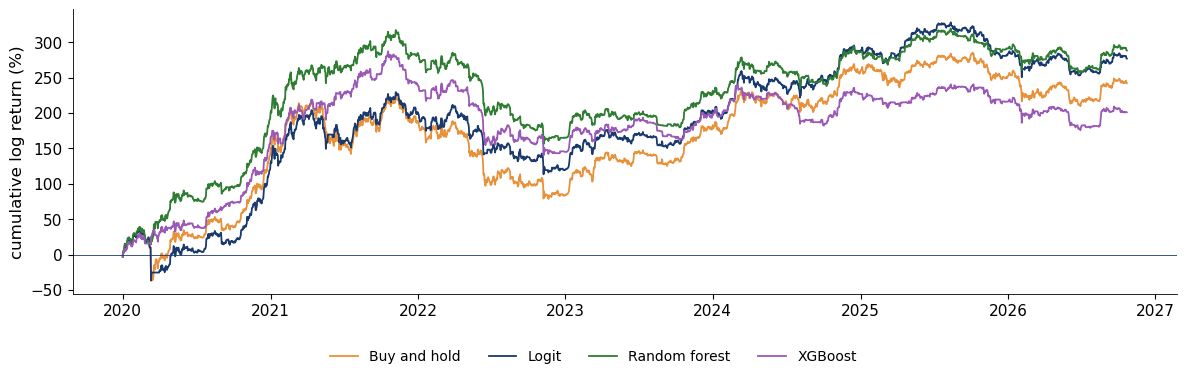

In [9]:
fig, ax = plt.subplots(figsize=(12, 3.8))
for m, col in [('Buy and hold', BTC), ('Logit', BLUE), ('Random forest', GREEN), ('XGBoost', ETH)]:
    ax.plot(dates[test], np.cumsum(G[m]), color=col, lw=1.3, label=m)
ax.axhline(0, color=BLUE, lw=0.6)
ax.set_ylabel('cumulative log return (%)')
legend_at_bottom(fig, ncol=4, bottom=0.1)
save_fig(fig, 'ba_l7_ml_equity')

## 2. Data snooping

### Many rules, one winner

If we test $N$ rules with no skill, the best one still has a high Sharpe ratio. For $N$ independent rules with true SR $= 0$, the expected maximum is approximately

$$ \mathrm{SR}_0 = \sqrt{V[\widehat{\mathrm{SR}}_n]}\left[(1-\gamma)\,\Phi^{-1}\!\left(1 - \tfrac1N\right) + \gamma\, \Phi^{-1}\!\left(1 - \tfrac{1}{N e}\right)\right], \quad \gamma \approx 0.5772 \text{ (Euler's constant)} . $$

The **probabilistic Sharpe ratio (PSR)** is the probability that the true SR exceeds a benchmark $\mathrm{SR}^*$, allowing for the skewness $\hat\gamma_3$
and kurtosis $\hat\gamma_4$ of $T$ daily returns:

$$ \mathrm{PSR}(\mathrm{SR}^*) = \Phi\!\left(\frac{(\widehat{\mathrm{SR}} - \mathrm{SR}^*)\sqrt{T-1}}{\sqrt{1 - \hat\gamma_3 \widehat{\mathrm{SR}} + \frac{\hat\gamma_4 - 1}{4}\widehat{\mathrm{SR}}^2}}\right) . $$

The **deflated Sharpe ratio (DSR)** $= \mathrm{PSR}(\mathrm{SR}_0)$ uses as benchmark the best SR expected by chance (Bailey and López de Prado, 2014).
White's (2000) reality check compares the best rule with the distribution of the best rule when no rule has skill. In the SR$_0$ and PSR
formulas the Sharpe ratio is in daily units (annualised SR divided by $\sqrt{365}$).

Design: 810 rules, 560 moving-average crossovers MA($s$, $l$) (long when the $s$-day average of the log price is above the $l$-day average) and
250 momentum rules MOM($k$) (long when the price is above its level $k$ days ago). Rules are selected on 2018–2022 and evaluated on
2023 – 23 October 2026, with the same 10 bp cost. Two null distributions of the best in-sample SR:

* a permutation illustration: 200 random permutations of the selection-period returns, which destroy any predictability but also volatility clustering;
* White's reality check: 1,000 stationary-bootstrap samples (random blocks with mean length 20 days) of the daily net returns of all rules, which keep
  volatility clustering; the null distribution is that of $\max_k (\mathrm{SR}^*_k - \widehat{\mathrm{SR}}_k)$.

The 810 rules are strongly correlated, so they are fewer than 810 independent trials; the cell also shows the DSR for smaller numbers of trials.
This cell takes about two minutes.

In [10]:
S0, S1 = pd.Timestamp('2018-01-01'), pd.Timestamp('2022-12-31')
lc = np.log(btc['close'].loc['2016-01-01':END])
ret = 100 * lc.diff()
rules = [('MA', s_, l_) for s_ in range(2, 51, 2) for l_ in range(10, 251, 10) if l_ > s_ + 4] + [('MOM', k, 0) for k in range(1, 251)]


def signals(lcs):
    """Positions (1 = long, 0 = cash) of all rules; the position for day t is decided at the close of t-1."""
    ma = {w: lcs.rolling(w).mean() for w in set([x[1] for x in rules if x[0] == 'MA'] + [x[2] for x in rules if x[0] == 'MA'])}
    out = {}
    for typ, a_, b_ in rules:
        sig = (ma[a_] > ma[b_]) if typ == 'MA' else (lcs - lcs.shift(a_) > 0)
        out[(typ, a_, b_)] = sig.astype(float).shift(1)
    return pd.DataFrame(out)


def sharpe_mat(sig, rr):
    pos = sig.values
    g = pos * rr.values[:, None] - COST * np.abs(np.diff(np.vstack([np.zeros((1, pos.shape[1])), pos]), axis=0))
    return g.mean(0) / g.std(0, ddof=1) * np.sqrt(365), g


SIG = signals(lc)
isel, osel = (ret.index >= S0) & (ret.index <= S1), (ret.index > S1) & (ret.index <= END)
SR_in, G_in = sharpe_mat(SIG[isel].fillna(0), ret[isel])
SR_out, _ = sharpe_mat(SIG[osel].fillna(0), ret[osel])
best = int(np.nanargmax(SR_in))
bh_in = ret[isel].mean() / ret[isel].std() * np.sqrt(365)
bh_out = ret[osel].mean() / ret[osel].std() * np.sqrt(365)

# deflated Sharpe ratio, daily units
g = G_in[:, best]; T = len(g)
sr = g.mean() / g.std(ddof=1)
g3, g4 = stats.skew(g), stats.kurtosis(g, fisher=False)
Ntr, EM = len(rules), 0.5772156649
sr0 = np.sqrt(np.var(SR_in / np.sqrt(365), ddof=1)) * ((1 - EM) * stats.norm.ppf(1 - 1 / Ntr) + EM * stats.norm.ppf(1 - 1 / (Ntr * np.e)))
den = np.sqrt(1 - g3 * sr + (g4 - 1) / 4 * sr ** 2)
dsr = stats.norm.cdf((sr - sr0) * np.sqrt(T - 1) / den)
psr = stats.norm.cdf(sr * np.sqrt(T - 1) / den)

# null: maximum in-sample SR over all rules when the selection-period returns are permuted
rng = np.random.default_rng(3)
mx = []
rv = ret.fillna(0).values.copy()
pos_in = np.where(isel)[0]
for b in range(200):
    rb = rv.copy(); rb[pos_in] = rng.permutation(rv[pos_in])
    lcb = pd.Series(lc.iloc[0] + np.cumsum(rb / 100), index=ret.index)
    srb, _ = sharpe_mat(signals(lcb)[isel].fillna(0), pd.Series(rb[pos_in], index=ret.index[isel]))
    mx.append(np.nanmax(srb))
mx = np.array(mx)

# DSR for different numbers of independent trials
dsr_n = {}
for Nn in [10, 25, 50, 100, 250, 810]:
    s0n = np.sqrt(np.var(SR_in / np.sqrt(365), ddof=1)) * ((1 - EM) * stats.norm.ppf(1 - 1 / Nn) + EM * stats.norm.ppf(1 - 1 / (Nn * np.e)))
    dsr_n[Nn] = stats.norm.cdf((sr - s0n) * np.sqrt(T - 1) / den)

# White's reality check: stationary bootstrap (mean block 20 days) of the panel of rule returns
rng2 = np.random.default_rng(11)
Tin = G_in.shape[0]
sr_hat = G_in.mean(0) / G_in.std(0, ddof=1) * np.sqrt(365)
rc = []
for b in range(1000):
    ix = np.empty(Tin, dtype=int); ix[0] = rng2.integers(Tin)
    jump = rng2.random(Tin) < 1 / 20
    newst = rng2.integers(Tin, size=Tin)
    for t_ in range(1, Tin):
        ix[t_] = newst[t_] if jump[t_] else (ix[t_ - 1] + 1) % Tin
    gb = G_in[ix]
    rc.append(np.nanmax(gb.mean(0) / gb.std(0, ddof=1) * np.sqrt(365) - sr_hat))
rc = np.array(rc)

typ, a_, b_ = rules[best]
print(f'Number of rules: {Ntr}; best rule in 2018-2022: {typ}({a_}' + (f', {b_})' if typ == 'MA' else ')'))
print(f'Sharpe ratio of the best rule: 2018-2022 {SR_in[best]:.2f}, 2023-2026 {SR_out[best]:.2f} '
      f'(rank {int(stats.rankdata(-SR_out)[best])} of {Ntr} in 2023-2026)')
print(f'Buy-and-hold Sharpe ratio: 2018-2022 {bh_in:.2f}, 2023-2026 {bh_out:.2f}')
print(f'Permutation illustration, best in-sample Sharpe ratio under permuted returns: mean {mx.mean():.2f}, 95th percentile {np.quantile(mx, 0.95):.2f}; '
      f'p-value of the winner {(mx >= SR_in[best]).mean():.3f}')
print(f"White's reality check (stationary bootstrap): p-value of the winner {(rc >= SR_in[best]).mean():.2f}")
print(f'Sharpe ratio of the best rule in daily units: {sr:.4f}; SR_0 in daily units: {sr0:.4f}')
print(f'Expected maximum SR by chance SR_0 (annualised): {sr0 * np.sqrt(365):.2f}')
print(f'PSR against zero: {psr:.2f}; deflated Sharpe ratio DSR = PSR(SR_0): {dsr:.2f}')
print('DSR by number of independent trials N:', {k: round(float(v), 2) for k, v in dsr_n.items()})
print(f'Rank (Spearman) correlation of in-sample and out-of-sample SR: {stats.spearmanr(SR_in, SR_out)[0]:.2f}; '
      f'Pearson correlation: {np.corrcoef(SR_in, SR_out)[0, 1]:.2f}')
print(f'Share of rules that beat buy-and-hold in 2023-2026: {100 * (SR_out > bh_out).mean():.0f}%')

Number of rules: 810; best rule in 2018-2022: MOM(2)
Sharpe ratio of the best rule: 2018-2022 0.84, 2023-2026 0.45 (rank 779 of 810 in 2023-2026)
Buy-and-hold Sharpe ratio: 2018-2022 0.04, 2023-2026 0.90
Permutation illustration, best in-sample Sharpe ratio under permuted returns: mean 0.55, 95th percentile 0.93; p-value of the winner 0.095
White's reality check (stationary bootstrap): p-value of the winner 0.31
Sharpe ratio of the best rule in daily units: 0.0438; SR_0 in daily units: 0.0304
Expected maximum SR by chance SR_0 (annualised): 0.58
PSR against zero: 0.97; deflated Sharpe ratio DSR = PSR(SR_0): 0.72
DSR by number of independent trials N: {10: 0.89, 25: 0.86, 50: 0.83, 100: 0.8, 250: 0.77, 810: 0.72}
Rank (Spearman) correlation of in-sample and out-of-sample SR: 0.15; Pearson correlation: 0.26
Share of rules that beat buy-and-hold in 2023-2026: 12%


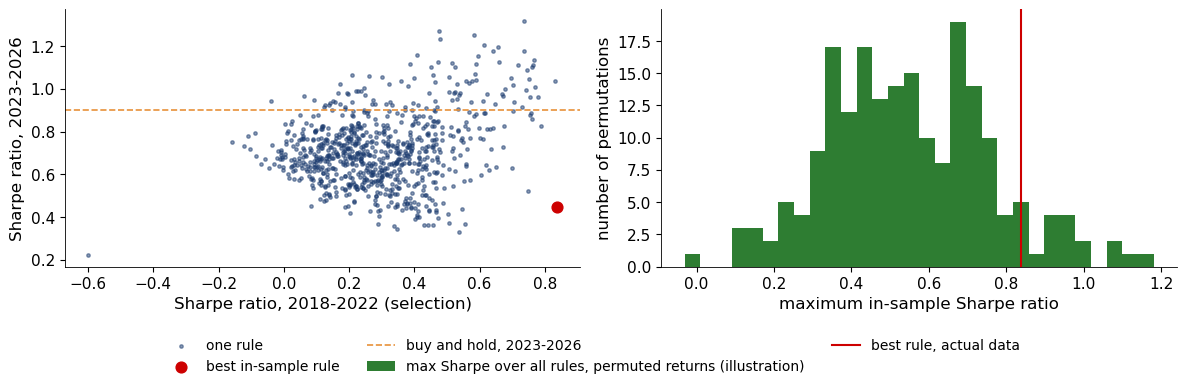

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.9))
ax[0].scatter(SR_in, SR_out, s=6, color=BLUE, alpha=0.5, label='one rule')
ax[0].scatter([SR_in[best]], [SR_out[best]], s=60, color=RED, zorder=5, label='best in-sample rule')
ax[0].axhline(bh_out, color=BTC, ls='--', lw=1.2, label='buy and hold, 2023-2026')
ax[0].set_xlabel('Sharpe ratio, 2018-2022 (selection)'); ax[0].set_ylabel('Sharpe ratio, 2023-2026')
ax[1].hist(mx, bins=30, color=GREEN, label='max Sharpe over all rules, permuted returns (illustration)')
ax[1].axvline(SR_in[best], color=RED, lw=1.5, label='best rule, actual data')
ax[1].set_xlabel('maximum in-sample Sharpe ratio'); ax[1].set_ylabel('number of permutations')
legend_at_bottom(fig, ncol=3, bottom=0.14)
save_fig(fig, 'ba_l7_snoop')

## 3. Risk forecasts: classical, machine learning and pretrained

### Six Value-at-Risk models

Each model forecasts $q_t$, the $\alpha$-quantile of $r_t$ given information up to day $t-1$ (a negative return); the one-day VaR at level $\alpha$ is
$\mathrm{VaR}_t = -q_t$, a positive loss in % (Lecture 3); $\alpha = 1\%$ and $5\%$.

Classical (Lecture 3):

* historical simulation (HS): the empirical $\alpha$-quantile of the last 500 returns;
* EWMA-N, an exponentially weighted moving average of squared returns with a Normal quantile: $\sigma_t^2 = 0.94\,\sigma_{t-1}^2 + 0.06\, r_{t-1}^2$, $q_t = \Phi^{-1}(\alpha)\sigma_t$;
* GARCH(1,1)-t, a generalised autoregressive conditional heteroskedasticity model with Student-$t$ errors:
  $q_t = \mu + \sigma_t\, t_\nu^{-1}(\alpha)\sqrt{(\nu-2)/\nu}$, refitted every 21 days on all data since 2015.

Machine learning:

* linear quantile regression (QReg, Koenker and Bassett, 1978) on heterogeneous autoregressive (HAR) volatility terms,
  $q_t = \beta_0 + \beta_1 |r_{t-1}| + \beta_2 \mathrm{RV}^{(5)}_{t-1} + \beta_3 \mathrm{RV}^{(22)}_{t-1} + \beta_4 \mathrm{RV}^{(66)}_{t-1} + \beta_5 \min(r_{t-1},0)$,
  with $\mathrm{RV}^{(k)}$ the $k$-day root mean square return; rolling 1,500 days, refitted every 21 days;
* gradient-boosted quantile trees (QGBM): 300 trees minimising the quantile loss on 9 features (returns, volatilities, volume change);
  rolling 1,500 days, refitted every 63 days.

Pretrained: Chronos-2, a transformer forecasting model trained on a large corpus of real and synthetic series, which returns quantiles directly.
It is used *zero-shot*: no parameter is fitted to Bitcoin; the input is the last 512 daily returns (next section).

Forecasts start on 1 June 2022 (so that 500 forecast errors exist before the test); the test period is 1 January 2024 – 23 October 2026.
This cell takes about half a minute.

In [12]:
ALPHAS = [0.01, 0.05]
F0, TT0 = pd.Timestamp('2022-06-01'), pd.Timestamp('2024-01-01')
CHRONOS_RELEASE = pd.Timestamp('2025-10-20')
NCAL = 500
n = len(r); vdates = r.index; R = r.values
fidx = np.where(vdates >= F0)[0]               # the forecast for day i uses data up to day i-1

# features known at the close of day t (to forecast t+1)
XQ = pd.DataFrame({'r0': r, 'r1': r.shift(1), 'r2': r.shift(2), 'a0': r.abs(),
                   'rv5': np.sqrt((r ** 2).rolling(5).mean()), 'rv22': np.sqrt((r ** 2).rolling(22).mean()),
                   'rv66': np.sqrt((r ** 2).rolling(66).mean()), 'dv': lv, 'neg': np.minimum(r, 0)}).values
Q = {m: {a: np.full(n, np.nan) for a in ALPHAS} for m in ['HS', 'EWMA-N', 'GARCH-t', 'QReg', 'QGBM']}

# HS and EWMA-N
s2 = np.var(R[:250]); ew = np.empty(n)
for i in range(n):
    ew[i] = s2                                  # variance forecast for day i from data up to i-1
    s2 = 0.94 * s2 + 0.06 * R[i] ** 2
for i in fidx:
    for a in ALPHAS:
        Q['HS'][a][i] = np.quantile(R[i - 500:i], a)
        Q['EWMA-N'][a][i] = stats.norm.ppf(a) * np.sqrt(ew[i])

# GARCH(1,1)-t, refitted every 21 days, parameters fixed within the block
for b0 in range(fidx[0], n, 21):
    b1 = min(b0 + 21, n)
    fit = arch_model(R[:b1], mean='Constant', vol='GARCH', p=1, q=1, dist='t').fit(last_obs=b0, disp='off')
    fc = fit.forecast(start=b0 - 1, horizon=1, reindex=False)
    mu, var = fc.mean.values[:, 0], fc.variance.values[:, 0]
    nu = fit.params['nu']
    for a in ALPHAS:
        Q['GARCH-t'][a][b0:b1] = mu[:b1 - b0] + stats.t.ppf(a, nu) * np.sqrt((nu - 2) / nu) * np.sqrt(var[:b1 - b0])

# quantile regression (HAR terms) and gradient-boosted quantile trees, rolling 1500 days
QR_COLS = [3, 4, 5, 6, 8]                       # |r|, RV5, RV22, RV66, min(r, 0)
for b0 in range(fidx[0], n, 21):
    b1 = min(b0 + 21, n)
    tr = np.arange(max(66, b0 - 1500), b0 - 1)  # feature row j predicts R[j+1]
    for a in ALPHAS:
        qr = sm.QuantReg(R[tr + 1], sm.add_constant(XQ[tr][:, QR_COLS])).fit(q=a, max_iter=5000)
        Q['QReg'][a][b0:b1] = sm.add_constant(XQ[b0 - 1:b1 - 1][:, QR_COLS], has_constant='add') @ qr.params
    if (b0 - fidx[0]) % 63 == 0:
        gb = {a: GradientBoostingRegressor(loss='quantile', alpha=a, n_estimators=300, max_depth=3, learning_rate=0.03,
                                           min_samples_leaf=20, subsample=0.8, random_state=1).fit(XQ[tr], R[tr + 1]) for a in ALPHAS}
    for a in ALPHAS:
        Q['QGBM'][a][b0:b1] = gb[a].predict(XQ[b0 - 1:b1 - 1])
print(f'Forecasts from {vdates[fidx[0]].date()} to {vdates[-1].date()} for', ', '.join(Q))

Forecasts from 2022-06-01 to 2026-10-23 for HS, EWMA-N, GARCH-t, QReg, QGBM


### The pretrained model (optional)

Chronos-2 needs PyTorch and the `chronos-forecasting` package and downloads the model weights (several hundred MB) from Hugging Face.
On a Colab CPU this adds several minutes, so it is switched off by default: with `RUN_CHRONOS = False` the comparison below covers the five
other models. Set `RUN_CHRONOS = True` and run the notebook again from this cell to add Chronos-2 to all tables and charts.

The checkpoint is pinned: Hugging Face model `amazon/chronos-2`, revision `29ec3766d36d6f73f0696f85560a422f50e8498c` (the version used for the
lecture, unchanged since 5 June 2026), with `chronos-forecasting` 2.3.2. Loading the model by name only would take whatever version is current
on the day you run the notebook, which may give different numbers.

In [13]:
RUN_CHRONOS = False

if RUN_CHRONOS:
    import importlib, subprocess, sys
    try:
        importlib.import_module('chronos')
    except ImportError:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'chronos-forecasting==2.3.2'], check=True)
    import torch
    from chronos import Chronos2Pipeline
    CHRONOS_REV = '29ec3766d36d6f73f0696f85560a422f50e8498c'                   # pinned checkpoint of amazon/chronos-2
    pipe = Chronos2Pipeline.from_pretrained('amazon/chronos-2', revision=CHRONOS_REV, device_map='cpu')
    Q['Chronos-2'] = {a: np.full(n, np.nan) for a in ALPHAS}
    for k in range(0, len(fidx), 128):
        ii = fidx[k:k + 128]
        ctx = [torch.tensor(R[i - 512:i], dtype=torch.float32) for i in ii]       # context: the last 512 daily returns
        qq, _ = pipe.predict_quantiles(ctx, prediction_length=1, quantile_levels=ALPHAS)
        for j, i in enumerate(ii):
            for cc, a in enumerate(ALPHAS):
                Q['Chronos-2'][a][i] = float(qq[j][0, 0, cc])
VMODELS = list(Q)
print('Models in the comparison:', ', '.join(VMODELS))

Models in the comparison: HS, EWMA-N, GARCH-t, QReg, QGBM


### How to score a quantile forecast

* Breach indicator $h_t = \mathbb{1}\{r_t < q_t\}$; the breach rate $\bar h$ should be close to $\alpha$.
* The Kupiec likelihood-ratio (LR) test checks $\bar h = \alpha$; the Christoffersen test checks that breaches are independent over time (Lecture 3).
* The **quantile score (QS)**, also called pinball loss,
  $$ \mathrm{QS}_\alpha(q, r) = (r - q)\left(\alpha - \mathbb{1}\{r < q\}\right) \ge 0, $$
  is *strictly consistent* for the quantile: its expectation is minimised only by the true conditional quantile. The breach rate is not:
  a forecast of $-\infty$ on 99% of days and $+\infty$ on 1% has a perfect breach rate and is useless.
* The Diebold–Mariano (DM) test compares two forecasts by the loss difference $d_t = \mathrm{QS}^{A}_t - \mathrm{QS}^{B}_t$:
  $$ \mathrm{DM} = \frac{\bar d}{\sqrt{\hat\Omega_d / T}} \;\overset{a}{\sim}\; N(0,1), \qquad \hat\Omega_d = \text{HAC (Newey–West) long-run variance.} $$

The breach rate answers "is the level right on average?"; the mean QS answers "how large is the average loss?", a loss whose expectation is
smallest for the true quantile. Below, every model is compared with GARCH-t by a two-sided DM test, with the mean QS difference and its 95% interval.
A non-significant DM test means that no difference is detected, not that the models are equally good.

In [14]:
def qs(y, q, a):
    """Quantile score (pinball loss)."""
    u = y - q
    return u * (a - (u < 0))


def kupiec(h, a):
    T, x = len(h), int(h.sum())
    p = x / T
    ll0 = (T - x) * np.log(1 - a) + x * np.log(a)
    ll1 = (T - x) * np.log(1 - p) + (x * np.log(p) if x > 0 else 0)
    return 2 * (ll1 - ll0), stats.chi2.sf(2 * (ll1 - ll0), 1)


def christ(h):
    """Christoffersen test of independence of breaches: p-value."""
    h = h.astype(int)
    n00 = ((h[:-1] == 0) & (h[1:] == 0)).sum(); n01 = ((h[:-1] == 0) & (h[1:] == 1)).sum()
    n10 = ((h[:-1] == 1) & (h[1:] == 0)).sum(); n11 = ((h[:-1] == 1) & (h[1:] == 1)).sum()
    p01, p11, p = n01 / (n00 + n01), (n11 / (n10 + n11) if n10 + n11 else 0), (n01 + n11) / (n00 + n01 + n10 + n11)
    L = lambda x, k: (k * np.log(x) if k else 0)
    ll1 = L(1 - p01, n00) + L(p01, n01) + L(1 - p11, n10) + L(p11, n11)
    ll0 = L(1 - p, n00 + n10) + L(p, n01 + n11)
    return stats.chi2.sf(2 * (ll1 - ll0), 1)


def dm(dl, lag=None):
    """Diebold-Mariano test with a Newey-West long-run variance: statistic and two-sided p-value."""
    T = len(dl); lag = lag or int(np.floor(4 * (T / 100) ** (2 / 9)))
    u = dl - dl.mean()
    lrv = u @ u / T + 2 * sum((1 - k / (lag + 1)) * (u[k:] @ u[:-k]) / T for k in range(1, lag + 1))
    t = dl.mean() / np.sqrt(lrv / T)
    return t, 2 * stats.norm.sf(abs(t))


def dm_ci(dl, lag=None):
    """Mean loss difference and its 95% interval, with the same Newey-West long-run variance as the DM test."""
    T = len(dl); lag = lag or int(np.floor(4 * (T / 100) ** (2 / 9)))
    u = dl - dl.mean()
    lrv = u @ u / T + 2 * sum((1 - k / (lag + 1)) * (u[k:] @ u[:-k]) / T for k in range(1, lag + 1))
    se = np.sqrt(lrv / T)
    return dl.mean(), dl.mean() - 1.96 * se, dl.mean() + 1.96 * se


tt = np.where((vdates >= TT0) & (vdates <= END))[0]
y = R[tt]; dd = vdates[tt]
post = dd > CHRONOS_RELEASE
VAR_RES = {}
for a in ALPHAS:
    base = qs(y, Q['GARCH-t'][a][tt], a)
    for m in VMODELS:
        q = Q[m][a][tt]; h = y < q; l = qs(y, q, a)
        dmean, dlo, dhi = dm_ci(l - base) if m != 'GARCH-t' else (np.nan, np.nan, np.nan)
        VAR_RES[(m, a)] = {'breach %': 100 * h.mean(), 'breaches': int(h.sum()), 'Kupiec p': kupiec(h, a)[1], 'Christoffersen p': christ(h),
                           'mean QS': l.mean(), 'DM p vs GARCH-t': dm(l - base)[1] if m != 'GARCH-t' else np.nan,
                           'QS minus GARCH-t': dmean, '95% low': dlo, '95% high': dhi, 'mean VaR (%)': -q.mean()}
VR = pd.DataFrame(VAR_RES).T
print(f'Test period {dd[0].date()} to {dd[-1].date()}, T = {len(tt)} days; expected breaches at 1%: {0.01 * len(tt):.1f}, at 5%: {0.05 * len(tt):.1f}')
for a in ALPHAS:
    print(f'\nVaR {100 * a:.0f}%:')
    print(VR.xs(a, level=1).round(4).to_string())

Test period 2024-01-01 to 2026-10-23, T = 1027 days; expected breaches at 1%: 10.3, at 5%: 51.4

VaR 1%:
         breach %  breaches  Kupiec p  Christoffersen p  mean QS  DM p vs GARCH-t  QS minus GARCH-t  95% low  95% high  mean VaR (%)
HS         1.1685      12.0    0.5972            0.5941   0.0842           0.4459            0.0039  -0.0061    0.0140        6.2278
EWMA-N     2.1422      22.0    0.0014            0.3261   0.0880           0.1843            0.0077  -0.0037    0.0191        5.5216
GARCH-t    0.6816       7.0    0.2765            0.7565   0.0803              NaN               NaN      NaN       NaN        6.9701
QReg       0.8763       9.0    0.6841            0.6898   0.0822           0.7129            0.0019  -0.0082    0.0120        7.4394
QGBM       1.0711      11.0    0.8209            0.6253   0.0848           0.3608            0.0045  -0.0051    0.0141        6.2428

VaR 5%:
         breach %  breaches  Kupiec p  Christoffersen p  mean QS  DM p vs GARCH-t  QS mi

### Breach rate and quantile score rank models differently

Left: breach rate of the VaR 1% forecasts against the 1% target. Right: mean quantile score (lower is better).

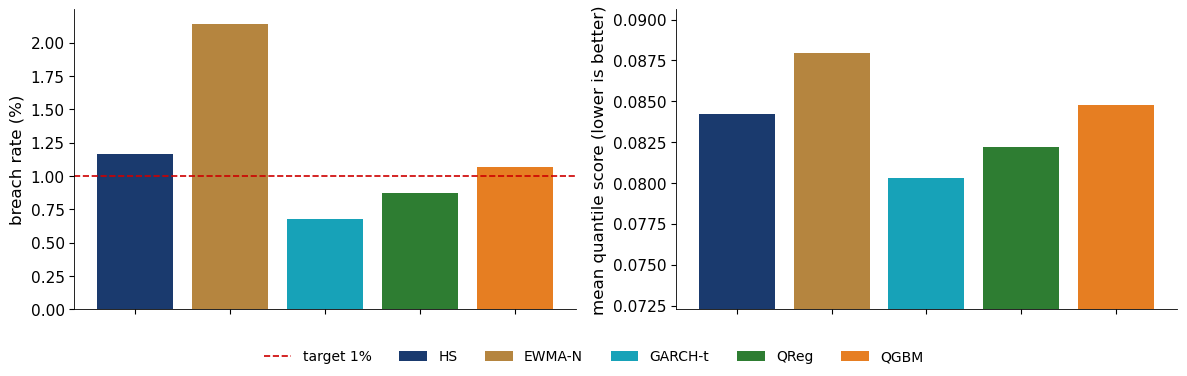

In [15]:
PAL = {'HS': BLUE, 'EWMA-N': GOLD, 'GARCH-t': TEAL, 'QReg': GREEN, 'QGBM': ORANGE, 'Chronos-2': ETH}
v1 = VR.xs(0.01, level=1)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
x = np.arange(len(VMODELS))
for k, m in enumerate(VMODELS):
    ax[0].bar(k, v1.loc[m, 'breach %'], color=PAL[m], label=m)
    ax[1].bar(k, v1.loc[m, 'mean QS'], color=PAL[m])
ax[0].axhline(1, color=RED, ls='--', lw=1.2, label='target 1%')
ax[0].set_ylabel('breach rate (%)'); ax[1].set_ylabel('mean quantile score (lower is better)')
ax[1].set_ylim(v1['mean QS'].min() * 0.9, v1['mean QS'].max() * 1.03)
for k_ in range(2):
    ax[k_].set_xticks(x); ax[k_].set_xticklabels([])
legend_at_bottom(fig, ncol=7, bottom=0.1)
save_fig(fig, 'ba_l7_var_models')

### VaR paths: machine learning can jump

Daily Bitcoin returns with the 1% return quantiles $q_t$ of the models (the VaR is $-q_t$). Trees do not extrapolate smoothly: an unusual
combination of inputs lands in an extreme leaf. The cell prints the largest one-day jump of the QGBM VaR and what GARCH-t did on the same day.

Largest QGBM VaR 1%: 35.4% on 2024-01-14 (previous day 7.3%); GARCH-t VaR 1% on the same days: 9.9% then 9.4%
Inputs of the three days before the jump (return in %, change in volume in %):
  2024-01-11: return -0.6%, volume -9%
  2024-01-12: return -7.9%, volume -5%
  2024-01-13: return -0.0%, volume -52%


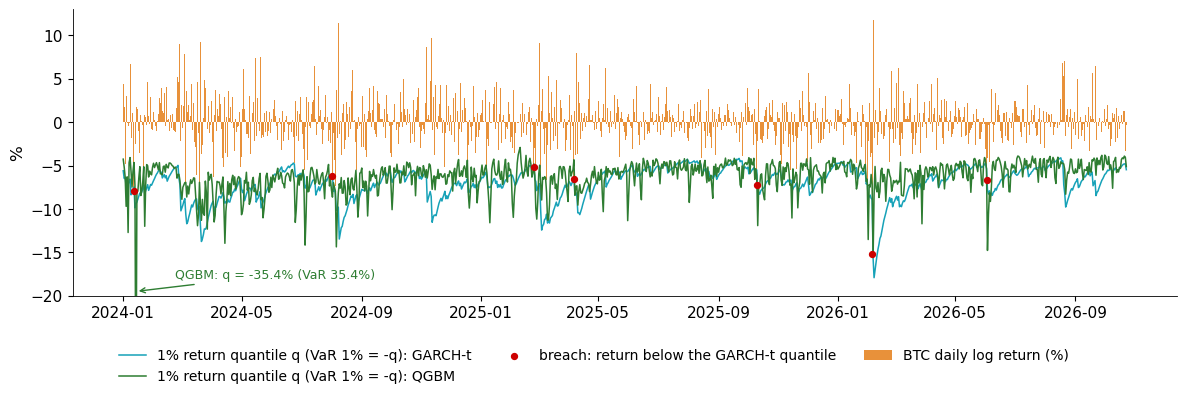

In [16]:
a = 0.01
qg, qgarch = Q['QGBM'][a][tt], Q['GARCH-t'][a][tt]
lo = int(np.argmin(qg))
print(f'Largest QGBM VaR 1%: {-qg[lo]:.1f}% on {dd[lo].date()} (previous day {-qg[lo - 1]:.1f}%); '
      f'GARCH-t VaR 1% on the same days: {-qgarch[lo - 1]:.1f}% then {-qgarch[lo]:.1f}%')
print('Inputs of the three days before the jump (return in %, change in volume in %):')
for j in range(tt[lo] - 3, tt[lo]):
    print(f'  {vdates[j].date()}: return {R[j]:+.1f}%, volume {100 * (np.exp(lv.iloc[j]) - 1):+.0f}%')

ref = 'Chronos-2' if RUN_CHRONOS else 'GARCH-t'
fig, ax = plt.subplots(figsize=(12, 4.0))
ax.bar(dd, y, color=BTC, width=1.0, label='BTC daily log return (%)')
for m in ['GARCH-t', 'QGBM'] + (['Chronos-2'] if RUN_CHRONOS else []):
    ax.plot(dd, Q[m][a][tt], color=GREEN if m == 'QGBM' else PAL[m], lw=1.1, label=f'1% return quantile q (VaR 1% = -q): {m}')   # QGBM green: orange is the return bars
hb = y < Q[ref][a][tt]
ax.scatter(dd[hb], y[hb], color=RED, s=18, zorder=5, label=f'breach: return below the {ref} quantile')
if RUN_CHRONOS:
    ax.axvline(CHRONOS_RELEASE, color=GOLD, ls=':', lw=1.5, label='Chronos-2 release (20 Oct 2025)')
ax.set_ylim(-20, 13)
ax.annotate(f'QGBM: q = {qg[lo]:.1f}% (VaR {-qg[lo]:.1f}%)', xy=(dd[lo], -19.5), xytext=(dd[lo] + pd.Timedelta(days=40), -18), color=GREEN, fontsize=9,
            arrowprops=dict(arrowstyle='->', color=GREEN))
ax.set_ylabel('%')
legend_at_bottom(fig, ncol=3, bottom=0.14)
save_fig(fig, 'ba_l7_var_paths')

### Pretrained models and look-ahead

A pretrained model may have seen the test period during training. Chronos-2 was released in October 2025; its training corpus may include
Bitcoin prices for 2024–2025, so only its forecasts after the release are clean; the earlier ones are a retrospective back-test.
The table splits the VaR 1% test period at 20 October 2025. Reproducibility also needs a fixed checkpoint (the pinned revision above).
Large language models (LLMs) have the same problem in a stronger form: any back-test of an LLM must use dates after its training cut-off.

In [17]:
pr = {}
for m in VMODELS:
    q = Q[m][0.01][tt]; h = y < q; l = qs(y, q, 0.01)
    pr[m] = {f'QS before release ({(~post).sum()} days)': l[~post].mean(), f'QS after release ({post.sum()} days)': l[post].mean(),
             'breach % after release': 100 * h[post].mean()}
print('VaR 1%, before and after the Chronos-2 release (20 October 2025):')
print(pd.DataFrame(pr).round(3).to_string())

VaR 1%, before and after the Chronos-2 release (20 October 2025):
                                 HS  EWMA-N  GARCH-t   QReg   QGBM
QS before release (659 days)  0.081   0.083    0.077  0.085  0.086
QS after release (368 days)   0.089   0.097    0.087  0.077  0.083
breach % after release        0.815   2.174    0.543  1.087  1.087


## 4. The limits of ML and AI in crypto finance

1. **Low signal**: the daily direction of Bitcoin is close to a coin toss (Section 1); flexibility adds variance, not signal.
2. **Non-stationarity**: regimes change (2020–2021 boom, 2022 crash, 2024 ETF era); what is learnt in one regime may not transfer (accuracy by year; the HS correction in the appendix).
3. **Few tail observations**: a 1% quantile from 500 days rests on 5 points, so tail models are noisy by construction.
4. **Data snooping**: testing many models and reporting the best inflates performance; report the number of trials and deflate (Section 2).
5. **Look-ahead**: pretrained models and LLMs may have seen the test period; features must be known at the forecast time; selection must use only past data.
6. **Survivorship**: today's list of coins excludes the dead ones, so results on survivors overstate performance.
7. **Explanation is not cause**: SHAP values and feature importances describe the model; causal claims need a design such as an event study (Lecture 6).

## Appendix (not examined)

### Correcting a forecast with its own errors

Forecast errors on a calibration window of $n$ days are $e_t = r_t - q_t$. If the forecast were right, $P(e_t < 0) = \alpha$.
The fitted correction is the empirical $\alpha$-quantile of the errors, $\hat c = \hat Q_\alpha(e_{t-n}, \dots, e_{t-1})$, and the corrected forecast with intensity $\lambda$ is

$$ q_t^{(\lambda)} = q_t + \lambda \hat c, \qquad \lambda = 0 \text{ (Raw)}, \;\; \tfrac12 \text{ (Half)}, \;\; 1 \text{ (Full)} . $$

*Static*: $\hat c$ fitted once on the 500 errors before the test and kept fixed. *Rolling*: refitted every day on the last 500 errors.

This is a rolling empirical-quantile correction. Full sets the breach rate on the calibration window to about $\alpha$ (exactly $\alpha$ only up to
ties and interpolation). It resembles split-conformal calibration, but the conformal coverage guarantee needs exchangeable errors, which a rolling
window of a time series does not ensure.

### Bias against estimation cost

Let $\delta$ be the true shift that would minimise the expected QS (the bias of the raw forecast), and $\hat c = \delta + \varepsilon$ with $V(\varepsilon) = \sigma_Q^2$.
With $f$ the density at the quantile, a second-order expansion gives the excess expected loss

$$ \Delta(\lambda) \approx \frac f2\left[(1-\lambda)^2\delta^2 + \lambda^2 \sigma_Q^2\right], \qquad \lambda^* = \frac{\delta^2}{\delta^2 + \sigma_Q^2} . $$

Hence Full beats Raw iff $\delta^2 > \sigma_Q^2$; Half beats Full iff $\delta^2 < 3\sigma_Q^2$; Half beats Raw iff $\delta^2 > \sigma_Q^2/3$.

### Monte Carlo: Raw, Half, Full

Returns are i.i.d. Student-$t_5$, $\alpha = 1\%$, $n = 500$; the raw forecast is the true quantile shifted by $\delta$; 20,000 replications.
Solid lines: Monte Carlo; dashed lines: the local theory $\Delta(\lambda)$.

Sampling sd of the fitted 1% correction (n = 500): sigma_Q = 0.392
Simulated crossings (delta / sigma_Q): Half beats Raw from 0.65 (theory 0.58), Half beats Full up to 1.40 (theory 1.73), Full beats Raw from 0.95 (theory 1)
No bias (delta = 0): excess expected QS x 1e3: Raw 0.00, Half 0.22, Full 0.92; expected breach rate with Full 1.19%


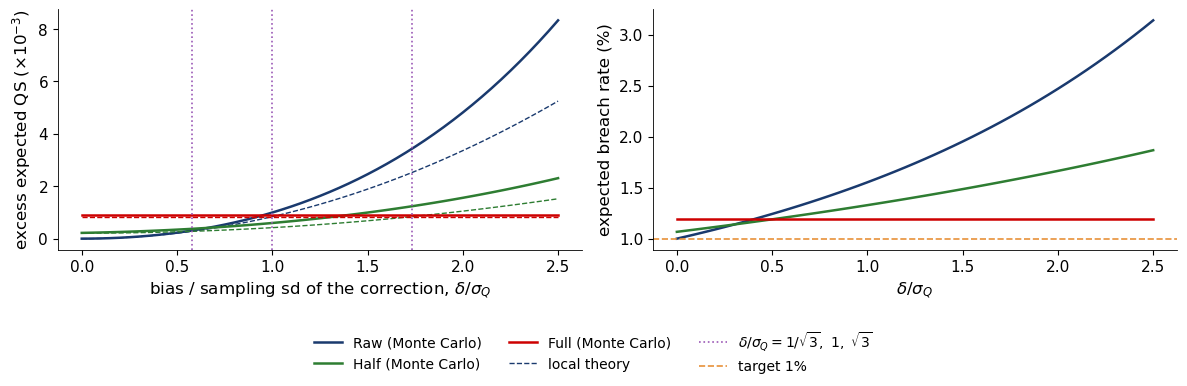

In [18]:
NU, A, NC, REPS = 5, 0.01, 500, 20000
qt5 = stats.t.ppf(A, NU); f5 = stats.t.pdf(qt5, NU)


def Lq(x):
    """Expected quantile score of the constant forecast x under t(NU)."""
    pe = -(NU + x ** 2) / (NU - 1) * stats.t.pdf(x, NU)          # integral of y f(y) up to x
    return A * (0 - x) + x * stats.t.cdf(x, NU) - pe


rng = np.random.default_rng(11)
qhat = np.quantile(stats.t.rvs(NU, size=(REPS, NC), random_state=rng), A, axis=1)
sq = qhat.std(ddof=1)                                            # sampling sd of the fitted correction
ratios = np.linspace(0, 2.5, 51)                                 # delta / sigma_Q
mc = {lam: [] for lam in [0, 0.5, 1]}
br = {lam: [] for lam in mc}
for rr in ratios:
    dlt = rr * sq
    cfit = qhat - qt5 - dlt
    for lam in mc:
        mc[lam].append(1e3 * np.mean(Lq(qt5 + dlt + lam * cfit) - Lq(qt5)))
        br[lam].append(100 * np.mean(stats.t.cdf(qt5 + dlt + lam * cfit, NU)))
mc = {k: np.array(v) for k, v in mc.items()}
theory = {lam: 1e3 * f5 / 2 * ((1 - lam) ** 2 * (ratios * sq) ** 2 + lam ** 2 * sq ** 2) for lam in mc}


def cross(a_, b_):
    d = np.diff(np.sign(a_ - b_)) != 0
    return ratios[np.argmax(d)] if d.any() else np.nan


print(f'Sampling sd of the fitted 1% correction (n = 500): sigma_Q = {sq:.3f}')
print(f'Simulated crossings (delta / sigma_Q): Half beats Raw from {cross(mc[0.5], mc[0]):.2f} (theory {1 / np.sqrt(3):.2f}), '
      f'Half beats Full up to {cross(mc[0.5], mc[1]):.2f} (theory {np.sqrt(3):.2f}), Full beats Raw from {cross(mc[1], mc[0]):.2f} (theory 1)')
print(f'No bias (delta = 0): excess expected QS x 1e3: Raw {mc[0][0]:.2f}, Half {mc[0.5][0]:.2f}, Full {mc[1][0]:.2f}; '
      f'expected breach rate with Full {br[1][0]:.2f}%')

fig, ax = plt.subplots(1, 2, figsize=(12, 3.9))
for lam, col, nm in [(0, BLUE, 'Raw'), (0.5, GREEN, 'Half'), (1, RED, 'Full')]:
    ax[0].plot(ratios, mc[lam], color=col, lw=1.8, label=f'{nm} (Monte Carlo)')
    ax[0].plot(ratios, theory[lam], color=col, lw=1.0, ls='--')
    ax[1].plot(ratios, br[lam], color=col, lw=1.8)
for v in [1 / np.sqrt(3), 1, np.sqrt(3)]:
    ax[0].axvline(v, color=ETH, ls=':', lw=1.2)
ax[0].plot([], [], color=BLUE, ls='--', lw=1.0, label='local theory')
ax[0].plot([], [], color=ETH, ls=':', lw=1.2, label=r'$\delta/\sigma_Q = 1/\sqrt{3},\ 1,\ \sqrt{3}$')
ax[1].axhline(1, color=BTC, ls='--', lw=1.2, label='target 1%')
ax[0].set_xlabel(r'bias / sampling sd of the correction, $\delta/\sigma_Q$'); ax[0].set_ylabel(r'excess expected QS ($\times 10^{-3}$)')
ax[1].set_xlabel(r'$\delta/\sigma_Q$'); ax[1].set_ylabel('expected breach rate (%)')
legend_at_bottom(fig, ncol=3, bottom=0.17)
save_fig(fig, 'ba_l7_lambda')

### Recalibrating the Bitcoin forecasts

For each model, $\hat c$ is the empirical quantile of its 500 forecast errors before 1 January 2024. Its standard error $\widehat{\mathrm{se}}$ comes
from a block bootstrap (2,000 resamples, blocks of 20 days); the ratio $\hat c^2/\widehat{\mathrm{se}}^2$ estimates $\delta^2/\sigma_Q^2$.
The table reports breach rates and mean QS of the Raw, Half and Full forecasts on the test period, the DM p-values of Half and Full against
Raw, and the QS of the rolling (daily refitted) Full correction. This cell takes about a minute.

In [19]:
def bboot_se(e, a, B=2000, L=20, seed=7):
    """Block-bootstrap standard error of the empirical a-quantile."""
    rng = np.random.default_rng(seed); T = len(e); out = []
    for _ in range(B):
        st = rng.integers(0, T, int(np.ceil(T / L)))
        idx = (st[:, None] + np.arange(L)[None]).ravel()[:T] % T
        out.append(np.quantile(e[idx], a))
    return np.std(out, ddof=1)


it0 = tt[0]
REC = {}
for a in ALPHAS:
    for m in VMODELS:
        q = Q[m][a][tt]; l = qs(y, q, a)
        e_cal = R[it0 - NCAL:it0] - Q[m][a][it0 - NCAL:it0]
        cst = np.quantile(e_cal, a)
        se = bboot_se(e_cal, a)
        roll = np.array([np.quantile(R[i - NCAL:i] - Q[m][a][i - NCAL:i], a) for i in tt])
        row = {'c_hat': cst, 'c2/se2': cst ** 2 / se ** 2}
        for nm, adj in [('Raw', 0), ('Half', 0.5 * cst), ('Full', cst), ('Full rolling', roll)]:
            row[f'breach % {nm}'] = 100 * (y < q + adj).mean()
            row[f'QS {nm}'] = qs(y, q + adj, a).mean()
        for nm, adj in [('Half', 0.5 * cst), ('Full', cst)]:
            row[f'DM p {nm} vs Raw'] = dm(qs(y, q + adj, a) - l)[1]
        REC[(m, a)] = row
REC = pd.DataFrame(REC).T
for a in ALPHAS:
    print(f'\nVaR {100 * a:.0f}%, static correction fitted on the 500 errors before 2024 (breach in %, QS = mean quantile score):')
    print(REC.xs(a, level=1).round(4).to_string())
hs = REC.loc[('HS', 0.01)]
print(f"\nHS, VaR 1%: Full correction changes the QS by {100 * (hs['QS Full'] / hs['QS Raw'] - 1):+.0f}%; "
      f"rolling Full correction QS {hs['QS Full rolling']:.4f} instead of {hs['QS Full']:.4f}")


VaR 1%, static correction fitted on the 500 errors before 2024 (breach in %, QS = mean quantile score):
          c_hat  c2/se2  breach % Raw  QS Raw  breach % Half  QS Half  breach % Full  QS Full  breach % Full rolling  QS Full rolling  DM p Half vs Raw  DM p Full vs Raw
HS       1.9112  2.1821        1.1685  0.0842         2.0448   0.0893         3.2132   0.1058                 1.5579           0.0908            0.1758            0.0087
EWMA-N  -1.1419  0.3573        2.1422  0.0880         1.6553   0.0831         0.9737   0.0816                 1.4606           0.0822            0.0474            0.1450
GARCH-t -0.0632  0.0010        0.6816  0.0803         0.6816   0.0804         0.6816   0.0805                 1.2658           0.0804            0.2053            0.2053
QReg     0.6322  0.5666        0.8763  0.0822         0.9737   0.0821         0.9737   0.0820                 1.1685           0.0835            0.9138            0.9249
QGBM     0.0825  0.0056        1.0711  0.0848

### Breach rate and loss after correction

Left: VaR 1% breach rates of Raw, Half and Full. Right: change of the mean QS against Raw ($\times 10^{-3}$); positive = worse.

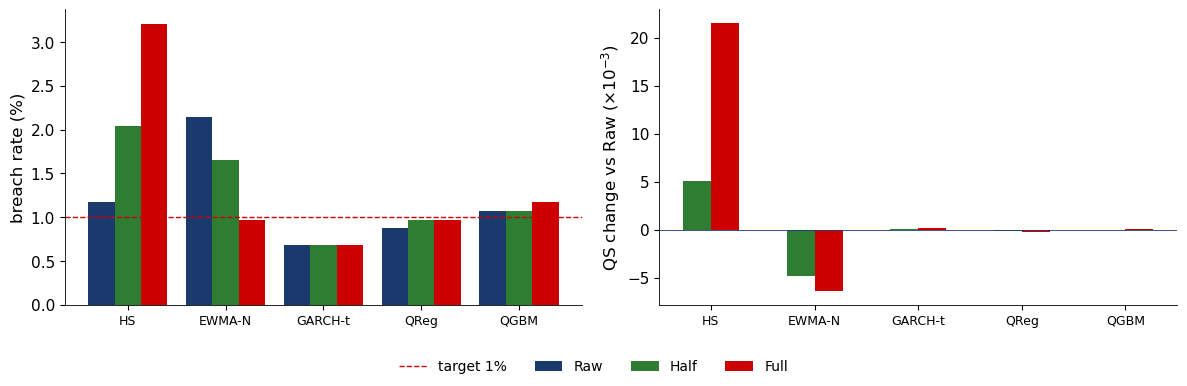

In [20]:
r1 = REC.xs(0.01, level=1)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.9))
w = 0.27
x = np.arange(len(VMODELS))
for k, (nm, col) in enumerate([('Raw', BLUE), ('Half', GREEN), ('Full', RED)]):
    ax[0].bar(x + (k - 1) * w, r1.loc[VMODELS, f'breach % {nm}'], w, color=col, label=nm)
    if nm != 'Raw':
        ax[1].bar(x + (k - 1.5) * w, 1000 * (r1.loc[VMODELS, f'QS {nm}'] - r1.loc[VMODELS, 'QS Raw']), w, color=col)
ax[0].axhline(1, color=RED, ls='--', lw=1.0, label='target 1%')
ax[1].axhline(0, color=BLUE, lw=0.6)
ax[0].set_ylabel('breach rate (%)'); ax[1].set_ylabel(r'QS change vs Raw ($\times 10^{-3}$)')
for k_ in range(2):
    ax[k_].set_xticks(x); ax[k_].set_xticklabels(VMODELS, fontsize=9)
legend_at_bottom(fig, ncol=4, bottom=0.1)
save_fig(fig, 'ba_l7_recal')

### Recalibration and the Basel traffic light

The Basel market-risk standard (MAR32.9–32.11) sorts the backtest of a 1% VaR over 250 days into a green (0–4 breaches), amber (5–9) and red
(10 or more) zone; "amber" was called "yellow" in the 1996 rules. The rule behind these limits: amber once the binomial probability of the breach count
reaches 95%, red at 99.99%. Applied to a crypto year of 365 days it gives green 0–6, amber 7–12, red 13+.
This is an illustration of the zones only: bank capital is computed for the whole trading book, not from a one-asset VaR.
The table counts the VaR 1% breaches of the Raw, Half and Full (static) forecasts by calendar year and gives the zone; the mean VaR is a positive loss in %.

In [21]:
def zone(k, nd):
    cdf = stats.binom.cdf(k, nd, 0.01)
    return 'red' if cdf >= 0.9999 else 'amber' if cdf >= 0.95 else 'green'


for nd in [250, 365]:
    print(f'{nd} days: green up to {max(k for k in range(30) if zone(k, nd) == "green")} breaches, '
          f'red from {min(k for k in range(30) if zone(k, nd) == "red")} breaches')
rows = []
for year in ['2024', '2025']:
    sel = dd.year == int(year)
    for m in VMODELS:
        cst = REC.loc[(m, 0.01), 'c_hat']
        q = Q[m][0.01][tt][sel]
        for nm, adj in [('Raw', 0), ('Half', cst / 2), ('Full', cst)]:
            k = int((y[sel] < q + adj).sum())
            rows.append(dict(year=year, model=m, rule=nm, days=int(sel.sum()), breaches=k, zone=zone(k, int(sel.sum())), mean_var=-(q + adj).mean()))
BZ = pd.DataFrame(rows)
print('\nBreaches of VaR 1% and Basel zone, by year:')
print(BZ.assign(cell=BZ.breaches.astype(str) + ' ' + BZ.zone).pivot_table(index='model', columns=['year', 'rule'], values='cell', aggfunc='first')
      .reindex(VMODELS)[[(yr, rl) for yr in ['2024', '2025'] for rl in ['Raw', 'Half', 'Full']]].to_string())
print('\nMean VaR 1% over 2024-2025 (%):')
print(BZ.groupby(['model', 'rule'])['mean_var'].mean().unstack().reindex(VMODELS)[['Raw', 'Half', 'Full']].round(2).to_string())

250 days: green up to 4 breaches, red from 10 breaches
365 days: green up to 6 breaches, red from 13 breaches

Breaches of VaR 1% and Basel zone, by year:
year        2024                         2025                   
rule         Raw      Half     Full       Raw     Half      Full
model                                                           
HS       6 green  10 amber   17 red   3 green  6 green  11 amber
EWMA-N   7 amber   6 green  3 green  10 amber  6 green   3 green
GARCH-t  2 green   2 green  2 green   3 green  3 green   3 green
QReg     3 green   4 green  4 green   2 green  2 green   2 green
QGBM     3 green   3 green  4 green   4 green  4 green   4 green

Mean VaR 1% over 2024-2025 (%):
rule      Raw  Half  Full
model                    
HS       6.28  5.33  4.37
EWMA-N   5.65  6.22  6.80
GARCH-t  7.08  7.11  7.14
QReg     7.61  7.30  6.98
QGBM     6.47  6.43  6.39


## References

* Pesaran, M. H., Timmermann, A. (1992). A simple nonparametric test of predictive performance. *Journal of Business & Economic Statistics*, 10(4), 461–465. [doi:10.1080/07350015.1992.10509922](https://doi.org/10.1080/07350015.1992.10509922)
* Lundberg, S. M., Lee, S.-I. (2017). A unified approach to interpreting model predictions. *Advances in Neural Information Processing Systems* 30.
* White, H. (2000). A reality check for data snooping. *Econometrica*, 68(5), 1097–1126. [doi:10.1111/1468-0262.00152](https://doi.org/10.1111/1468-0262.00152)
* Bailey, D. H., López de Prado, M. (2014). The deflated Sharpe ratio. *Journal of Portfolio Management*, 40(5), 94–107. [doi:10.3905/jpm.2014.40.5.094](https://doi.org/10.3905/jpm.2014.40.5.094)
* Koenker, R., Bassett, G. (1978). Regression quantiles. *Econometrica*, 46(1), 33–50. [doi:10.2307/1913643](https://doi.org/10.2307/1913643)
* Ansari, A. F., et al. (2025). Chronos-2: from univariate to universal forecasting. [arXiv:2510.15821](https://arxiv.org/abs/2510.15821)
* Gneiting, T., Resin, J. (2023). Regression diagnostics meets forecast evaluation. *Electronic Journal of Statistics*. [doi:10.1214/23-EJS2180](https://doi.org/10.1214/23-EJS2180)
* Basel Committee on Banking Supervision (2019). Minimum capital requirements for market risk, MAR32 (backtesting). [PDF](https://www.bis.org/publications/201901-standards-minimum-capital-requirements-market-risk.pdf)